# OpenET GEESEBAL
## Image Mapping Examples
This example shows how you could build an ET image collection by mapping the model image class over a GEE Landsat image collection.

In [ ]:
import pprint
import ee
from IPython.display import Image
import sys

import openet.geesebal as model

In [ ]:
# Initialize the Earth Engine package, initiating the authentication flow if needed.
try:
    ee.Initialize()
except ee.EEException:
    ee.Authenticate()
    ee.Initialize()

In [6]:
ndvi_palette = ['#EFE7E1', '#003300']
et_palette = [
    'DEC29B', 'E6CDA1', 'EDD9A6', 'F5E4A9', 'FFF4AD', 'C3E683', '6BCC5C', 
    '3BB369', '20998F', '1C8691', '16678A', '114982', '0B2C7A']

image_size = 768
landsat_cs = 30

### Input parameters

In [15]:
collection_id = 'LANDSAT/LC08/C02/T1_L2'

# et_reference_source = 'projects/ee-openetbrazil/assets/meteorological/daily/era5-land/sa'
# et_reference_band = 'eto_asce'
# et_reference_factor = 1
# et_reference_resample = 'nearest'

et_reference_source = 'IDAHO_EPSCOR/GRIDMET'
et_reference_band = 'ETr_ASCE'
et_reference_factor = 1
et_reference_resample = 'nearest'

# Date range you want to aggregate ET over
# End date is inclusive
start_date = '2017-06-01'
end_date = '2017-09-01'

test_point = ee.Geometry.Point(-121.5265, 38.7399)

# Hard code the study area and CRS
study_area = ee.Geometry.Rectangle(-122.00, 38.50, -121.00, 39.0)
study_region = study_area.bounds(1, 'EPSG:4326').coordinates().getInfo()
study_crs = 'EPSG:32610'

### Landsat 8 Collection 1 SR Images
Build the input image collection

In [16]:
landsat_coll = ee.ImageCollection(collection_id)\
    .filterDate(start_date, end_date)\
    .filterBounds(test_point)

# Check which images are in the collection
pprint.pprint(list(landsat_coll.aggregate_histogram('system:index').getInfo().keys()))

['LC08_044033_20170614',
 'LC08_044033_20170630',
 'LC08_044033_20170716',
 'LC08_044033_20170801',
 'LC08_044033_20170817']


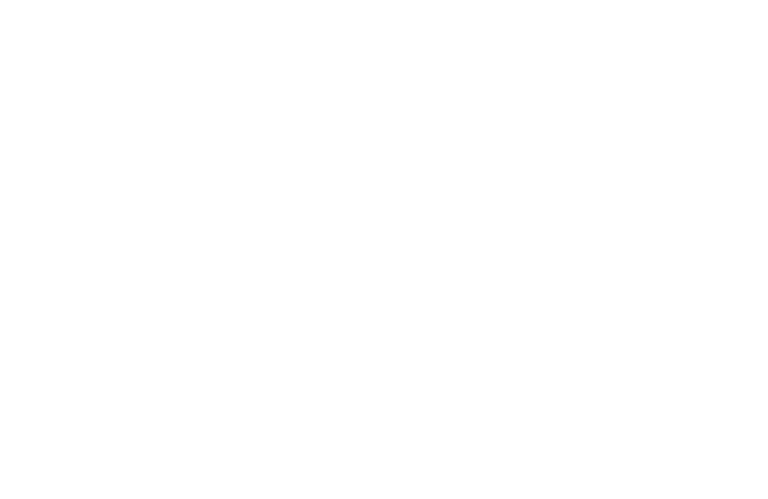

In [25]:
image_url = landsat_coll.first().select([3, 2, 1]).multiply([0.0001, 0.0001, 0.0001])\
    .getThumbURL({'min': 0.0, 'max': 0.3, 
                  'region': study_region, 'dimensions': image_size})
Image(image_url, embed=True, format='png')

In [19]:
landsat_crs = ee.Image(landsat_coll.first()).select('SR_B3').projection().getInfo()['crs']
landsat_region = ee.Image(landsat_coll.first()).geometry().bounds(1, 'EPSG:4326').coordinates().getInfo()
# landsat_dt = ee.Date(landsat_img.get('system:time_start'))

### ET Image Collection

In [21]:
def compute_et(image):
    """Return an ET image for each input Landsat 8 C1 SR image
    
    Since etr parameters are not set, this will default to using GRIDMET ETr
    """
    return model.Image.from_landsat_c2_sr(
        image, 
        et_reference_source=et_reference_source, 
        et_reference_band=et_reference_band).et
    
# Build the SSEBop model for each image then compute and return ET
et_coll = ee.ImageCollection(landsat_coll.map(compute_et))

# pprint.pprint(ee.Image(et_coll.first()).getInfo())

In [23]:
def compute_et(image):
    return model.Image.from_landsat_c2_sr(
        image, 
        et_reference_source=et_reference_source, 
        et_reference_band=et_reference_band).et

# Build the SSEBop model for each image then compute and return ET
et_coll = ee.ImageCollection(landsat_coll.map(compute_et))

# pprint.pprint(ee.Image(et_coll.first()).getInfo())

In [24]:
# Note, a thumbnail can't be generated for a full Landsat image at scale=30
image_url = ee.Image(et_coll.mean())\
    .getThumbURL({'min': 0, 'max': 12, 'palette': et_palette, 
                  'region': study_region, 'dimensions': image_size})
#     .reproject(crs=landsat_crs, scale=100)\
Image(url=image_url, embed=True, format='png')

EEException: Too many concurrent aggregations.

### Custom Image Class Parameters 
It is also possible to pass custom parameter to the Image class as long as they are the same for all images.

For this example, the reference ET collection ID and band are being set to GRIDMET, and the temperature difference threshold is being changed from the default of 15 to 1 (to show that it works).

In [10]:
# TODO: Switch this example to a GEESEBAL parameter
# def custom_et(image):
#     image_obj = model.Image.from_landsat_c1_sr(
#         image, 
#         et_reference_source='IDAHO_EPSCOR/GRIDMET', 
#         et_reference_band='etr',
#         dt=2)
#     return image_obj.et
    
# # Build the model for each image then compute and return ET
# et_coll = ee.ImageCollection(landsat_coll.map(custom_et))

In [11]:
# image_url = ee.Image(et_coll.mean())\
#     .reproject(crs=landsat_crs, scale=100)\
#     .getThumbURL({'min': 0, 'max': 12, 'palette': et_palette, 
#                   'region': study_region, 'dimensions': 768})
# Image(url=image_url, embed=True, format='png')

### Map the calculate method over the Landsat collection

In [12]:
def compute_vars(image):
    """Return an ET image for each input Landsat 8 C1 SR image"""
    return model.Image\
        .from_landsat_c1_sr(
            image, 
            et_reference_source=et_reference_source, 
            et_reference_band=et_reference_band)\
        .calculate(['et', 'et_fraction'])
        # .calculate(['et', 'et_reference', 'et_fraction'])
    
# Build the SSEBop model for each image then compute and return ET, ETr, and ETf
vars_coll = ee.ImageCollection(landsat_coll.map(compute_vars))

# pprint.pprint(ee.Image(et_coll.first()).getInfo())

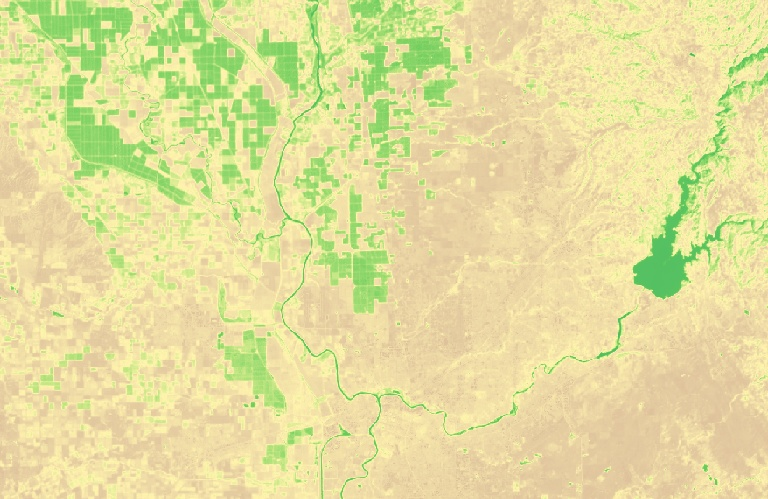

In [13]:
image_url = ee.Image(vars_coll.select(['et']).mean())\
    .reproject(crs=landsat_crs, scale=100)\
    .getThumbURL({'min': 0, 'max': 12, 'palette': et_palette, 
                  'region': study_region, 'dimensions': 768})
Image(url=image_url, embed=True, format='png')